In [1]:
import os
import fitsio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, interpn
from scipy.signal import fftconvolve
from scipy.constants import pi, h, c, e, m_e, k, epsilon_0, physical_constants
import healpy as hp



In [2]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'cmr10' 
plt.rcParams['font.size'] = 15
plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rc('axes', unicode_minus=False)

# Read in Spectrometer Response Output

In [ ]:
model = 5
data = np.load() ### Path to beam-diluted RRL spectra with spectrometer response applied. Shape is (time, frequency)
data.shape


(650, 204801)

In [4]:
fmin = 10
fmax = 50

freq_ = np.arange(10e6, 50e6 + 25e3, 25e3, dtype=np.int32)
offsets = np.arange(-390.625 * 32, 390.625 * 32 + 10, 390.625/2)
freq = (freq_[:, None] + offsets).ravel()
freqs = np.unique(freq[(freq >= fmin * 1e6) & (freq <= fmax * 1e6)]) / 1e6


Text(0.5, 0, 'Frequency [MHz]')

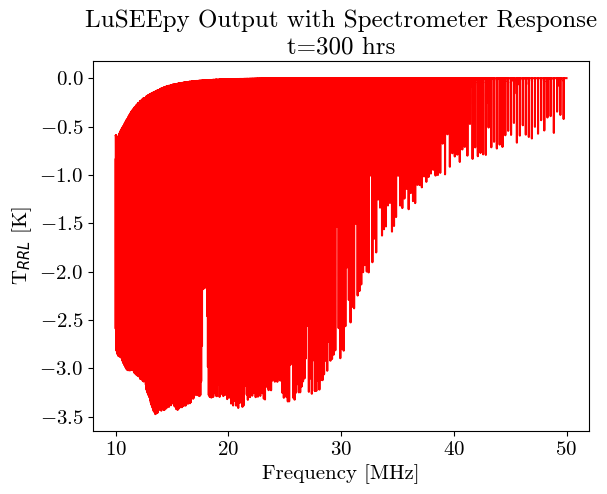

In [5]:
t = 300 

plt.title(f"LuSEEpy Output with Spectrometer Response\nt={t} hrs")
plt.plot(freqs, data[t,:], color = "red")
plt.ylabel(r"T$_{RRL}$ [K]")
plt.xlabel("Frequency [MHz]")

In [ ]:
rrl_freq_fpath = ### Path to frequencies where CRRLs are centered
rrl_freq = np.load(rrl_freq_fpath)
rrl_freq = np.sort(rrl_freq) / 1e6
rrl_freq

array([10.00867774, 10.04328987, 10.07806177, 10.11299438, 10.14808862,
       10.18334543, 10.21876574, 10.25435052, 10.29010071, 10.32601727,
       10.36210118, 10.39835342, 10.43477495, 10.47136678, 10.5081299 ,
       10.54506532, 10.58217403, 10.61945707, 10.65691546, 10.69455022,
       10.7323624 , 10.77035305, 10.80852321, 10.84687396, 10.88540635,
       10.92412147, 10.9630204 , 11.00210423, 11.04137407, 11.08083102,
       11.12047619, 11.16031071, 11.20033572, 11.24055234, 11.28096174,
       11.32156506, 11.36236347, 11.40335815, 11.44455027, 11.48594103,
       11.52753163, 11.56932326, 11.61131715, 11.65351453, 11.69591662,
       11.73852468, 11.78133995, 11.82436369, 11.86759717, 11.91104168,
       11.9546985 , 11.99856893, 12.04265428, 12.08695587, 12.13147502,
       12.17621307, 12.22117137, 12.26635128, 12.31175416, 12.3573814 ,
       12.40323436, 12.44931447, 12.49562312, 12.54216173, 12.58893173,
       12.63593456, 12.68317167, 12.73064453, 12.7783546 , 12.82

In [7]:
tmin = 0
tmax = 650
points = (np.arange(tmin, tmax), freqs)
def interp_spectra(t, f):
    '''
    f is frequency in MHz
    t is time step (0-649)
    '''
    return interpn(points, data, [[t, f]], method='linear')

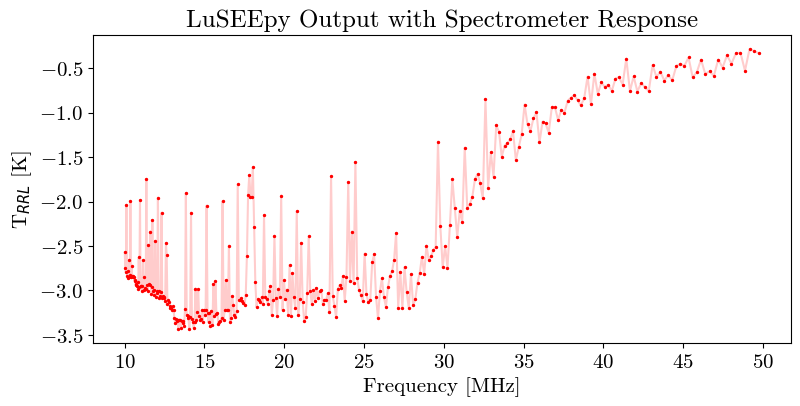

In [8]:
t = 300 

plt.figure(figsize=(9,4))
plt.title(f"LuSEEpy Output with Spectrometer Response")
plt.scatter(rrl_freq, [interp_spectra(t = t, f = f) for f in rrl_freq], color = "red", s = 2)
plt.plot(rrl_freq, [interp_spectra(t = t, f = f) for f in rrl_freq], color = "red", alpha = 0.2)
plt.ylabel(r"T$_{RRL}$ [K]")
plt.xlabel("Frequency [MHz]")
plt.show()

In [9]:
interpolated_data = []

# Get the amplitudes of the RRLs at the frequencies where CRRLs are centered
for t in range(650):
    interpolated_data.append([interp_spectra(t = t, f = f) for f in rrl_freq])

interpolated_data = np.array(interpolated_data)[:, :, 0]

In [11]:
nvals = np.arange(509, 870)

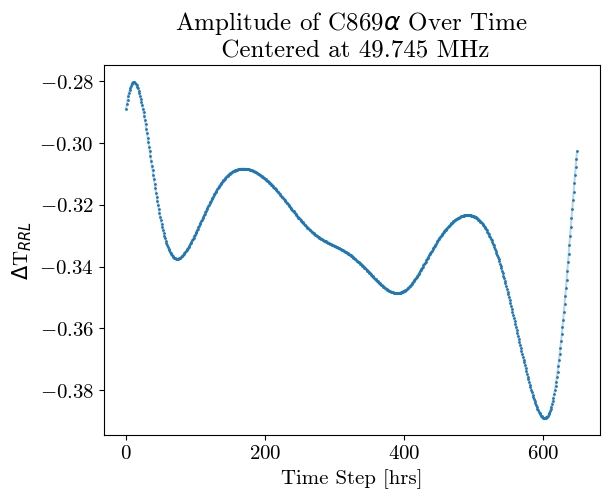

In [15]:
rrl_idx = 360

p = np.argsort(rrl_freq)

plt.scatter(np.arange(0, 650), interpolated_data[:,rrl_idx], s = 1)
plt.plot(np.arange(0, 650), interpolated_data[:,rrl_idx], alpha = 0.3)
plt.xlabel("Time Step [hrs]")
plt.ylabel(r"$\Delta$T$_{RRL}$")
plt.title(f"Amplitude of C{nvals[p][rrl_idx]}"+r"$\alpha$ Over Time"+f"\n Centered at {np.round(rrl_freq[rrl_idx], 3)} MHz")
plt.show()

In [16]:
# Average the amplitude of RRLs in time
mean_rrl_temp = np.mean(interpolated_data, axis = 0)
mean_rrl_temp.shape

(361,)

# Read in the ULSA Maps

In [ ]:
ulsa_map_path = ### Path to luseepy output where sky model is ULSA maps with no RRLs added
header   = dict(fitsio.read_header(ulsa_map_path))

from astropy.io import fits

with fits.open(ulsa_map_path) as f:
    ulsa_maps = f['data'].data
    freq_luseepy = f['freq'].data
    products = f["products"].data
    # Reconstruct complex blackbody normalization
    N = (
        f["blackbody_normalization_real"].data
        + 1j * f["blackbody_normalization_imag"].data
    )
    
    product_names = [p[0] for p in products]
    i00 = product_names.index("00R")
    ulsa_temp = ulsa_maps[:, i00, :] / N[:, 0, 0].real


In [20]:
# Average over time
mean_sky_brightness = np.mean(ulsa_temp, axis = 0)
mean_sky_brightness.shape

(361,)

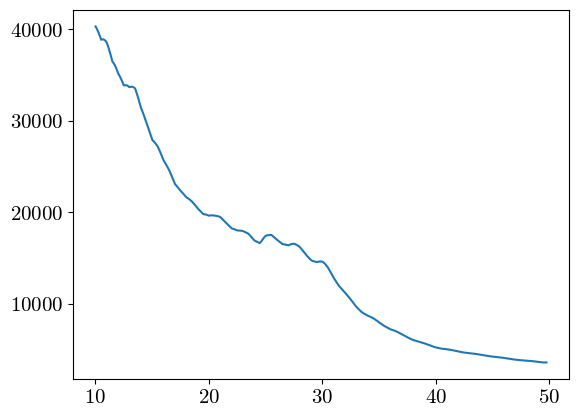

In [21]:
plt.plot(rrl_freq, mean_sky_brightness)
plt.show()

# Calculate Integration Time

$SNR = \frac{T_A}{T_{sys}}\sqrt{\Delta \nu \tau}$ 

$\tau = \frac{ \left(SNR \frac{T_{sys}}{T_{A}} \right)^2 }{\Delta \nu}$

In [22]:
SNR = 5
bandwidth = 390.625 
ratio = mean_rrl_temp / mean_sky_brightness


In [23]:
tau = ((SNR / ratio) ** 2) / bandwidth

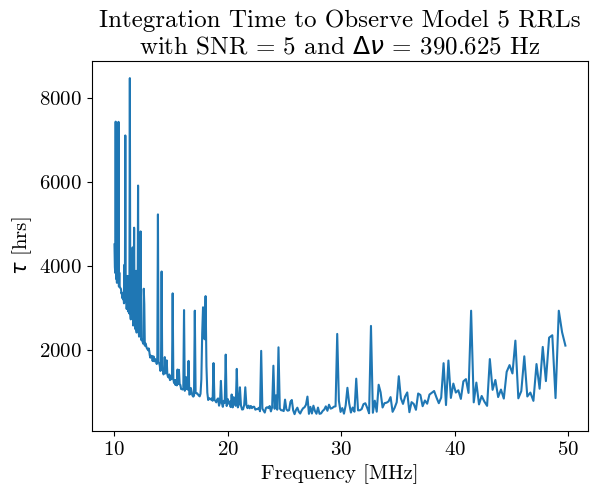

In [24]:
plt.plot(rrl_freq, tau/3600)
plt.xlabel("Frequency [MHz]")
plt.ylabel(r"$\tau$ [hrs]")
plt.title(f"Integration Time to Observe Model {model} RRLs\nwith SNR = {SNR} and "+r"$\Delta \nu$ = 390.625 Hz")
plt.show()

In [26]:
print(f"Model {model}")
print(f"Max: {np.max(tau/3600)}") # Integration time in hours
print(f"Min: {np.min(tau/3600)}")

Model 5
Max: 8460.965414966025
Min: 487.55630930077405
